# Nearest neighbor analysis

This Jupyter notebook does the following:

- Load apartment and supermarket data and prepare point GeoDataFrames.
- Subset ALDI and VOLG supermarkets, then find the nearest one for each apartment.
- Merge the nearest supermarket details into the apartment data.
- Summarise distances with descriptive statistics and a boxplot.
- Display apartments and their nearest supermarkets on maps and export the results to CSV.

## Libraries and settings

In [1]:
# Install specific version of scipy

# Libraries
import os
from pathlib import Path
import folium
import platform
import pandas as pd
import seaborn as sns
import geopandas as gdp
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Import functions to calculate nearest-neighbors
import nn_functions as nn

# Locate lesson data when launched from the workspace root or lesson folder
lesson_dir = Path.cwd()
if not (lesson_dir / "supermarkets_data_enriched.csv").exists():
    lesson_dir = lesson_dir / "Week_11" / "03_Python_NearestNeighbor_Analysis"
os.chdir(lesson_dir)

## Prepare geodataframe of apartments data

In [2]:
# Read apartments data
df_app = pd.read_csv('apartments_data_enriched.csv', 
                      sep=',', 
                      encoding='utf-8')[['web-scraper-order', 
                                         'lat', 
                                         'lon',
                                         'address_raw',
                                         'bfs_number',
                                         'bfs_name']]

# Convert data frame of apartments data to geodataframe
df_app_geo = gdp.GeoDataFrame(df_app, 
                        geometry=gdp.points_from_xy(df_app['lon'], 
                                                    df_app['lat']))

# Set Coordinate Reference System (CRS)
df_app_geo = df_app_geo.set_crs(4326, allow_override=True)
df_app_geo.head()

,web-scraper-order,lat,lon,address_raw,bfs_number,bfs_name,geometry
0,1662023695-433,47.255714,8.804976,"Sunnenbergstrasse 15, 8633 Wolfhausen, ZH",112,Bubikon,POINT (8.80498 47.25571)
1,1662023720-634,47.254879,8.793746,"Blumenbergstrasse 7, 8633 Wolfhausen, ZH",112,Bubikon,POINT (8.79375 47.25488)
2,1662023745-834,47.277386,8.800306,"8608 Bubikon, ZH",112,Bubikon,POINT (8.80031 47.27739)
3,1662023701-503,47.277386,8.800306,"8608 Bubikon, ZH",112,Bubikon,POINT (8.80031 47.27739)
4,1662023745-820,47.361378,8.533339,"Lavaterstr. 63, 8002 Zürich, ZH",261,Zürich,POINT (8.53334 47.36138)


## Prepare geodataframe of supermarkets data

In [3]:
# Read supermarket data and select those with know brand
df_sup = pd.read_csv('supermarkets_data_enriched.csv', 
                     sep=',', 
                     encoding='utf-8')[['id', 
                                        'lat', 
                                        'lon',
                                        'brand',
                                        'bfs_number',
                                        'bfs_name']].dropna()
print(df_sup.shape)

# Convert data frame of apartments data to geodataframe
df_sup_geo = gdp.GeoDataFrame(df_sup, 
                       geometry=gdp.points_from_xy(df_sup['lon'], 
                                                   df_sup['lat']))

# Set Coordinate Reference System (CRS)
df_sup_geo = df_sup_geo.set_crs(4326, allow_override=True)

# Create case-insensitive subsets for the two requested supermarket brands
brand_names = df_sup_geo['brand'].str.strip().str.upper()
df_sup_aldi = df_sup_geo.loc[brand_names == 'ALDI'].copy()
df_sup_volg = df_sup_geo.loc[brand_names == 'VOLG'].copy()
df_sup_geo = pd.concat([df_sup_aldi, df_sup_volg]).sort_index()

print('ALDI locations:', len(df_sup_aldi))
print('VOLG locations:', len(df_sup_volg))
df_sup_geo.head()

(2009, 6)
ALDI locations: 124
VOLG locations: 210


,id,lat,lon,brand,bfs_number,bfs_name,geometry
1,280130028,47.155492,9.039666,ALDI,3315,Schänis,POINT (9.03967 47.15549)
9,75749133,47.340967,8.530601,ALDI,261,Zürich,POINT (8.5306 47.34097)
18,267344304,47.388322,8.496596,ALDI,261,Zürich,POINT (8.4966 47.38832)
60,482763774,47.413733,8.539034,ALDI,261,Zürich,POINT (8.53903 47.41373)
72,765567648,47.373756,8.537687,ALDI,261,Zürich,POINT (8.53769 47.37376)


## Identify closest supermarkets per apartment and calculate its distance

In [4]:
# Closest supermarket of each apartment
closest_supermarkets = nn.nearest_neighbor(df_app_geo, 
                                           df_sup_geo, 
                                           return_dist=True)

print(len(closest_supermarkets), '==', len(df_app_geo))

# Rename the geometry of closest stops gdf so that we can easily identify it
closest_supermarkets = closest_supermarkets.rename(columns={'geometry': 'closest_sup_geom'})
closest_supermarkets.head()

870 == 870


,id,lat,lon,brand,bfs_number,bfs_name,closest_sup_geom,distance
0,338156406,47.269671,8.820879,Volg,112,Bubikon,POINT (8.82088 47.26967),1961.760419
1,623872894,47.251620,8.767989,Volg,153,Hombrechtikon,POINT (8.76799 47.25162),1977.485909
2,338156406,47.269671,8.820879,Volg,112,Bubikon,POINT (8.82088 47.26967),1773.412687
3,338156406,47.269671,8.820879,Volg,112,Bubikon,POINT (8.82088 47.26967),1773.412687
4,765567648,47.373756,8.537687,ALDI,261,Zürich,POINT (8.53769 47.37376),1414.805970


## Merge closest supermarkets to apartments

In [5]:
# Merge supermarkets to apartments
result = pd.merge(closest_supermarkets, 
                  df_app_geo, 
                  left_index=True, 
                  right_index=True)[['web-scraper-order',
                                     'address_raw',
                                     'lat_y',
                                     'lon_y',
                                     'id',
                                     'brand',
                                     'geometry',
                                     'closest_sup_geom',
                                     'distance']]

# Rename columns
results = result.rename(columns={'lat_y': 'lat',
                                 'lon_y': 'lon'},
                        inplace = True)
result.head()

,web-scraper-order,address_raw,lat,lon,id,brand,geometry,closest_sup_geom,distance
0,1662023695-433,"Sunnenbergstrasse 15, 8633 Wolfhausen, ZH",47.255714,8.804976,338156406,Volg,POINT (8.80498 47.25571),POINT (8.82088 47.26967),1961.760419
1,1662023720-634,"Blumenbergstrasse 7, 8633 Wolfhausen, ZH",47.254879,8.793746,623872894,Volg,POINT (8.79375 47.25488),POINT (8.76799 47.25162),1977.485909
2,1662023745-834,"8608 Bubikon, ZH",47.277386,8.800306,338156406,Volg,POINT (8.80031 47.27739),POINT (8.82088 47.26967),1773.412687
3,1662023701-503,"8608 Bubikon, ZH",47.277386,8.800306,338156406,Volg,POINT (8.80031 47.27739),POINT (8.82088 47.26967),1773.412687
4,1662023745-820,"Lavaterstr. 63, 8002 Zürich, ZH",47.361378,8.533339,765567648,ALDI,POINT (8.53334 47.36138),POINT (8.53769 47.37376),1414.805970


## Summary statistics of distance to closest supermarkets

In [6]:
result['distance'].describe()

count     870.000000
mean     1707.240826
std      1256.012313
min         2.006449
25%       703.008962
50%      1398.797767
75%      2408.982219
max      6039.245055
Name: distance, dtype: float64

## Boxplot of distance to closest supermarkets

<Axes: xlabel='distance'>

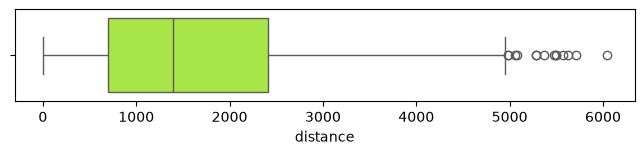

In [7]:
plt.figure(figsize=(8,1.2))
plt.ticklabel_format(style='plain')
sns.boxplot(x=result['distance'], 
            color="greenyellow")

## Plotting map with apartments and nearest supermarkets

In [8]:
# Polygonmap als .json-File (WGS84)
polys = gdp.read_file("GEN_A4_GEMEINDEN_2019_epsg4326.json")

# Marker symbols
url_01 = 'https://raw.githubusercontent.com/pointhi/leaflet-color-markers/master/img/marker-icon-blue.png'
url_02 = 'https://raw.githubusercontent.com/pointhi/leaflet-color-markers/master/img/marker-icon-gold.png'

# Initialisierung der Map
m = folium.Map(location=[47.44, 8.65], 
               zoom_start=11, tiles='OpenStreetMap')

# Plot Polygonmap of municipalities
folium.Choropleth(
    geo_data=polys,
    name='polys',
    fill_color='transparent',
    line_color='darkred').add_to(m)

# Add lat/lon of apartments
for i in range(0, len(result)):
    folium.Marker(location=(result.iloc[i]['lat'],  
                            result.iloc[i]['lon']), 
                  popup=result.iloc[i]['address_raw'],
                  icon=folium.features.CustomIcon(url_01,icon_size=(14, 23))).add_to(m)
    
# Add lat/lon of apartments
for i in range(0, len(closest_supermarkets)):
    folium.Marker(location=(closest_supermarkets.iloc[i]['lat'],  
                            closest_supermarkets.iloc[i]['lon']), 
                  popup=closest_supermarkets.iloc[i]['brand'],
                  icon=folium.features.CustomIcon(url_02,icon_size=(14, 23))).add_to(m)

# Layer control
folium.LayerControl().add_to(m)

# Save the interactive map for later viewing
m.save('nearest_neighbor_analysis_aldi_volg.html')

# Plot map
m

## Save map of apartments and their nearest ALDI/VOLG supermarkets

The static map shows the apartment points, unique nearest ALDI/VOLG locations, and the links between them.

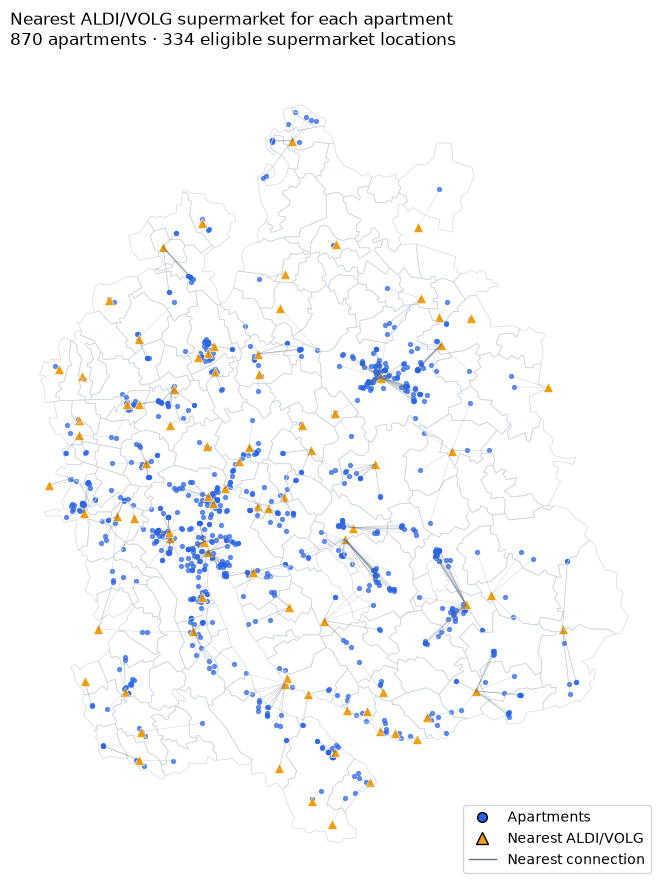

In [9]:
from matplotlib.lines import Line2D
from shapely.geometry import LineString

# Reproject to LV95 so the map and nearest-neighbor links use metric coordinates
boundaries_plot = polys.to_crs('EPSG:2056')
apartments_plot = gdp.GeoDataFrame(
    result, geometry='geometry', crs=df_app_geo.crs
).to_crs('EPSG:2056')
nearest_plot = closest_supermarkets.set_geometry('closest_sup_geom').to_crs('EPSG:2056')
connection_lines = gdp.GeoSeries(
    [
        LineString([apartment.coords[0], supermarket.coords[0]])
        for apartment, supermarket in zip(result['geometry'], result['closest_sup_geom'])
    ],
    crs='EPSG:4326',
).to_crs('EPSG:2056')

fig, ax = plt.subplots(figsize=(11, 9))
boundaries_plot.boundary.plot(ax=ax, color='#cbd5e1', linewidth=0.45)
connection_lines.plot(ax=ax, color='#64748b', linewidth=0.35, alpha=0.3)
apartments_plot.plot(ax=ax, color='#2563eb', markersize=8, alpha=0.65)
nearest_plot.drop_duplicates(subset='id').plot(
    ax=ax, color='#f59e0b', marker='^', markersize=50, edgecolor='white', linewidth=0.4
)
ax.set_title(
    f'Nearest ALDI/VOLG supermarket for each apartment\n'
    f'{len(result):,} apartments · {len(df_sup_geo):,} eligible supermarket locations',
    loc='left',
)
ax.legend(handles=[
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#2563eb', label='Apartments', markersize=7),
    Line2D([0], [0], marker='^', color='none', markerfacecolor='#f59e0b', label='Nearest ALDI/VOLG', markersize=8),
    Line2D([0], [0], color='#64748b', linewidth=1, label='Nearest connection'),
], loc='lower right')
ax.set_axis_off()
fig.tight_layout()
fig.savefig('nearest_neighbor_analysis_aldi_volg.png', dpi=200, bbox_inches='tight')
plt.show()

## Save data to file

In [10]:
result.to_csv('apartments_data_with_supermarkets.csv', 
              sep=",", 
              encoding='utf-8',
              index=False)

### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [11]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1070-azure
Datetime: 2026-11-27 08:09:27
Python Version: 3.11.18
-----------------------------------
